# Exercise 3: Heredero Louis & Amacker Olivier

# Gradient Boosting with Random Forests and related topics

In this last notebook, we will explore the Gradient Boosting technique for classification. This technique combines the principles of gradient boosting and random forests by sequentially fitting decision trees to the errors of the previous trees, improving model accuracy while maintaining the benefits of ensemble methods.

### Import and preprocess data

In [1]:
# IMPORTS PACKAGES
import os
import time

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.stats import randint
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
path = os.path.join(os.getcwd(), "EEG_mouse_data.csv")
data_mice = pd.read_csv(path)

In [3]:
def norm_0_1(data):
    # Calculate the minimum and maximum values for each column (feature)
    min_vals = data.min(axis=0)
    max_vals = data.max(axis=0)
    # print(max_vals)

    # Perform min-max scaling
    normalized_data = (data - min_vals) / (max_vals - min_vals)
    return normalized_data


# CREATE X AND Y FROM DATAFRAME
X = np.vstack([data_mice.iloc[i, 2:] for i in np.arange(len(data_mice))])
X = norm_0_1(X)
Y = data_mice["state"].values

# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

### GradientBoostingClassifier

This time, the hyperparameters have already been fine-tuned, so you don't need to adjust them yourself. Simply execute the cell to train the model; it might take 1 or 2 minutes.

Q3.1: Two additional hyperparameters were added compared to the RandomForestClassifier. What are these hyperparameters, and what roles do they play?

**A3.1**: The parameters are:
  - `learning_rate`: weight to tweak how much the model parameters are modified on each iteration
  - `subsample`: fraction of the dataset given to each tree

In [4]:
from sklearn.ensemble import GradientBoostingClassifier

# Define hyperparameters for Gradient Boosting
hyperparameters_gb = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": 4,
    "subsample": 0.5,
    "min_samples_leaf": 15,
    "max_features": 20,
}

# Create a Gradient Boosting classifier with the specified hyperparameters
gb_classifier = GradientBoostingClassifier(**hyperparameters_gb, random_state=0)

# Fit the model on the training data
start_time = time.time()
gb_classifier.fit(X_train, Y_train)
fit_time = time.time() - start_time

print("Gradient Boosting model trained")
print(f"Training time: {fit_time:.2f} seconds")

Gradient Boosting model trained
Training time: 72.38 seconds


### FINAL MODEL EVALUATION

Accuracy on Training Set: 0.9556954214488461
Accuracy on Test Set: 0.9123889437314906
Classification Report for Training Set:
              precision    recall  f1-score       support
n              0.954428  0.964212  0.959295   5365.000000
r              0.954663  0.686220  0.798483   1074.000000
w              0.956461  0.980649  0.968404   9767.000000
accuracy       0.955695  0.955695  0.955695      0.955695
macro avg      0.955184  0.877027  0.908728  16206.000000
weighted avg   0.955669  0.955695  0.954128  16206.000000
Classification Report for Test Set:
              precision    recall  f1-score      support
n              0.918782  0.920785  0.919782  1376.000000
r              0.751678  0.413284  0.533333   271.000000
w              0.918384  0.963825  0.940556  2405.000000
accuracy       0.912389  0.912389  0.912389     0.912389
macro avg      0.862948  0.765965  0.797890  4052.000000
weighted avg   0.907369  0.912389  0.906266  4052.000000


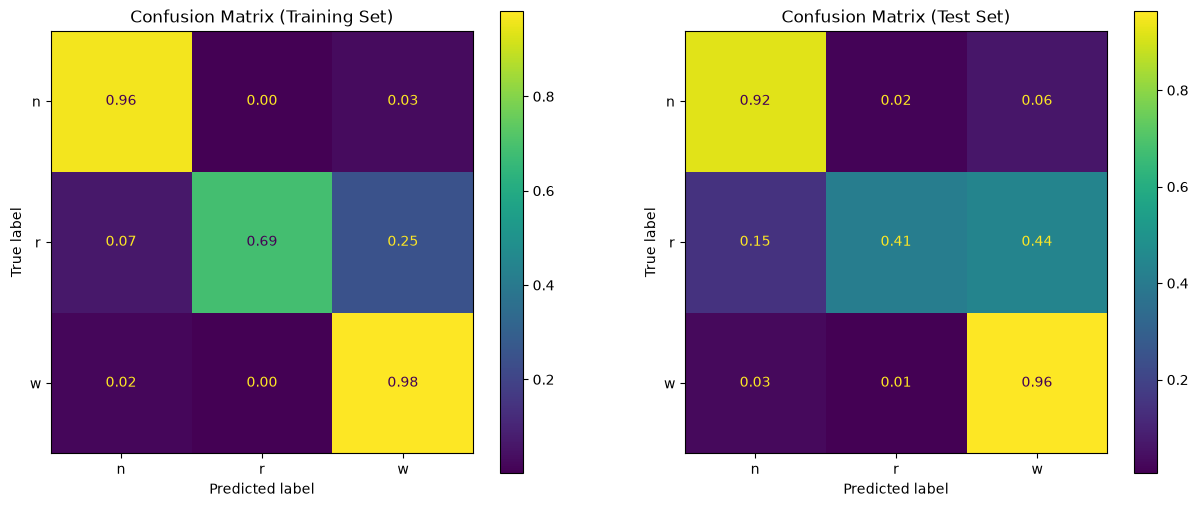

In [5]:
# Make predictions
train_prediction = gb_classifier.predict(X_train)
test_prediction = gb_classifier.predict(X_test)
test_prediction

# Calculate accuracy
train_accuracy = accuracy_score(Y_train, train_prediction)
test_accuracy = accuracy_score(Y_test, test_prediction)

# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Confusion matrix for the training set
cm_train = confusion_matrix(Y_train, train_prediction, normalize="true")
disp_train = ConfusionMatrixDisplay(
    confusion_matrix=cm_train, display_labels=gb_classifier.classes_
)
_ = disp_train.plot(ax=axs[0], values_format=".2f")
_ = axs[0].set_title("Confusion Matrix (Training Set)")
# Confusion matrix for the test set
cm_test = confusion_matrix(Y_test, test_prediction, normalize="true")
disp_test = ConfusionMatrixDisplay(
    confusion_matrix=cm_test, display_labels=gb_classifier.classes_
)
_ = disp_test.plot(ax=axs[1], values_format=".2f")
_ = axs[1].set_title("Confusion Matrix (Test Set)")

# Display accuracy for both sets
print("Accuracy on Training Set:", train_accuracy)
print("Accuracy on Test Set:", test_accuracy)

# Classification report for the training set
classification_metrics_train = classification_report(
    Y_train, train_prediction, output_dict=True
)
report_df_train = pd.DataFrame(classification_metrics_train).transpose()
print("Classification Report for Training Set:")
print(report_df_train)

# Classification report for the test set
classification_metrics_test = classification_report(
    Y_test, test_prediction, output_dict=True
)
report_df_test = pd.DataFrame(classification_metrics_test).transpose()
print("Classification Report for Test Set:")
print(report_df_test)

plt.show()

The cell above summarizes performance of the GradientBoostingClassifier.

Q3.2: Comment the results. Compare these results with the ones obtained with the RandomForestClassifier. Compare more specifically the precision, the recall and the f1-score of the 'r' class obtained with GradientBoostingClassifier and RandomForestClassifier. What are your conclusions?

**A3.2**: We have greatly improved the precision on 'r', but the recall has decreased slightly. The F1 score has also improved a bit. The other classes have also globally improved. We can conclude that this model is generally better at classifying our data.

NOTE: It is interesting to note that, in a real-world scenario, performances for this task could be further improved. For example, you could apply more advanced feature engineering techniques, or even incorporate other sensors, such as an electromyograph (EMG) for recording the electrical activity in skeletal muscles. Nevertheless, these aspects are beyond the scope of this practical work.

## Extra work: Test KNN classifier

Create and train the classifier

In [6]:
hyperparameters_knn = {
    "n_neighbors": 15,
    "weights": "distance",
    "metric": "euclidean",
    "p": 2,
    "algorithm": "auto",
}


knn_classifier = KNeighborsClassifier(**hyperparameters_knn)

label_encoder = LabelEncoder()
Y_train = label_encoder.fit_transform(Y_train)
Y_test = label_encoder.transform(Y_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


start_time = time.time()
knn_classifier.fit(
    X_train_scaled,
    Y_train,
)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",15
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


Measure the model performance

Accuracy on Test Set: 0.8849950641658441
Classification Report for Test Set:
              precision    recall  f1-score      support
0              0.907738  0.886628  0.897059  1376.000000
1              0.868421  0.121771  0.213592   271.000000
2              0.873783  0.970062  0.919409  2405.000000
accuracy       0.884995  0.884995  0.884995     0.884995
macro avg      0.883314  0.659487  0.676687  4052.000000
weighted avg   0.884955  0.884995  0.864614  4052.000000


<Figure size 1500x600 with 0 Axes>

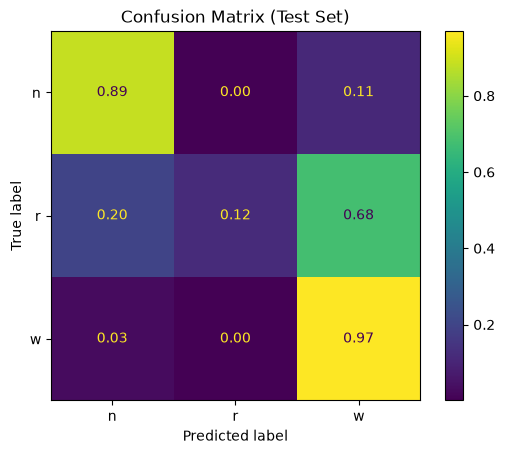

In [7]:
# Make predictions
knn_train_prediction = knn_classifier.predict(X_train_scaled)
knn_test_prediction = knn_classifier.predict(X_test_scaled)

# Calculate accuracy
knn_test_accuracy = accuracy_score(Y_test, knn_test_prediction)

# Create a figure with two subplots
plt.figure(figsize=(15, 6))


# Confusion matrix for the test set
knn_cm_test = confusion_matrix(Y_test, knn_test_prediction, normalize="true")
knn_disp_test = ConfusionMatrixDisplay(
    confusion_matrix=knn_cm_test, display_labels=gb_classifier.classes_
)
_ = knn_disp_test.plot(values_format=".2f")
_ = plt.title("Confusion Matrix (Test Set)")

# Display accuracy for both sets
print("Accuracy on Test Set:", knn_test_accuracy)


# Classification report for the test set
knn_classification_metrics_test = classification_report(
    Y_test, knn_test_prediction, output_dict=True
)
knn_report_df_test = pd.DataFrame(knn_classification_metrics_test).transpose()
print("Classification Report for Test Set:")
print(knn_report_df_test)

plt.show()

### Conclusion

As we can see on the confusion matrix and the metrics, the KNN classifier also suffers from the unbalanced dataset issue. 

Interestingly the performances of this model are worse than even the basic random forest made in exercise 1 (without the `max_depth=4` and `min_samples=20`) which means that KNN might not be the best model for this specific task